# LAB 12 — Stage 05: Temporal & Group-Aware Data Splitting, Cross-Validation Design & Evaluation Contract

**Scope:** Bu notebook'un çıktısı bir **model değildir** -- bir **Evaluation Protocol**'dür.
Stage 06-14 boyunca keyfî biçimde değiştirilmeyecek training/validation/protected-test
sınırlarını, group-aware cross-validation fold'larını ve leakage-prevention invariant'larını
tanımlar.

## Mandatory Engineering Principle

**Question → Hypothesis → Evidence → Alternatives → Decision → Validation → Documentation.**
Temporal ordering, group isolation ve prediction-time availability, performans testinden önce
sağlanması gereken **zorunlu metodolojik kısıtlardır** -- bunlar yalnızca p-value veya
correlation ile doğrulanmaya çalışılmaz.

## Learning Objectives

1. Random Splitting ve Temporal Splitting farkını, Group/Temporal/Target Leakage'ı açıklamak.
2. Shipment-level atomic splitting ve group integrity oluşturmak.
3. Chronological Train/Validation/Protected-Test split tasarlamak.
4. Expanding-Window Cross-Validation fold'ları üretmek.
5. Gap/Purging/Embargo kavramlarını ayırt etmek.
6. Reproducible split manifest ve protocol fingerprint üretmek.
7. Stage 06 için leakage-safe bir preprocessing-fit contract hazırlamak.

In [1]:
# Same environment setup pattern as LAB02-LAB12 Stage 01-04.
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config  # noqa: E402

config = load_config()
lab12_cfg = config["lab12"]
stage05_cfg = lab12_cfg["stage05"]
RANDOM_SEED = config["random_seed"]
print("Project root:", PROJECT_ROOT)
print("stage05 config loaded:", list(stage05_cfg.keys()))

Project root: C:\Users\pc\ml-labs
stage05 config loaded: ['enabled', 'split', 'grouping', 'cross_validation', 'temporal_gap', 'evaluation', 'reproducibility', 'artifacts']


---

## Section 02 — Repository & Decision Recovery

Herhangi bir split oluşturmadan önce, önceki stage'lerin gerçek artifact'larından kararları
geri yüklüyoruz.

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]

with open(ARTIFACT_DIR / "dataset_profile.json", encoding="utf-8") as f:
    stage03_profile = json.load(f)
with open(ARTIFACT_DIR / "stage03_5_qualification_gate.json", encoding="utf-8") as f:
    stage03_5_gate = json.load(f)
reference_resolution_summary = pd.read_csv(ARTIFACT_DIR / "reference_resolution_summary.csv")
with open(ARTIFACT_DIR / "stage04_qualification_gate.json", encoding="utf-8") as f:
    stage04_gate = json.load(f)
with open(ARTIFACT_DIR / "stage04_eda_protocol.json", encoding="utf-8") as f:
    stage04_eda_protocol = json.load(f)
with open(ARTIFACT_DIR / "stage04_population_profile.json", encoding="utf-8") as f:
    stage04_population_profile = json.load(f)

print("Dataset SHA-256 (Stage 01-03):", stage03_profile["SHA256"])
print("Stage03.5 -> Stage04 readiness:", stage03_5_gate["stage04_readiness"])
print("Stage04 -> Stage05 readiness:", stage04_gate["stage05_readiness"])
print("EDA cutoff (Stage04):", stage04_eda_protocol["fixed_eda_cutoff"])
print("Population counts (Stage04):", stage04_population_profile["population_counts"])

cross_shipment_refs = int(reference_resolution_summary.loc[
    reference_resolution_summary["Metric"] == "Resolution_Status__Resolved - Cross Shipment", "Value"
].values[0])
print("\nCross-shipment cost-anchor dependencies (Stage 03.5):", cross_shipment_refs)
assert cross_shipment_refs == 0, "A nonzero cross-shipment dependency count would require a connected-component grouping layer -- not needed here."
print("No cross-group cost-anchor dependency exists -- a simple ASN/DN group key is sufficient (no connected-component grouping layer required).")

Dataset SHA-256 (Stage 01-03): 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Stage03.5 -> Stage04 readiness: CONDITIONAL GO
Stage04 -> Stage05 readiness: CONDITIONAL GO
EDA cutoff (Stage04): 2013-12-31
Population counts (Stage04): {'Population_A_Structural_Audit': 7030, 'Population_B_EDA_Historical': 5551, 'Population_C_Labeled_EDA': 4987, 'Population_D_Protected_Future': 1479, 'Missing_or_invalid_date_shipments': 0}

Cross-shipment cost-anchor dependencies (Stage 03.5): 0
No cross-group cost-anchor dependency exists -- a simple ASN/DN group key is sufficient (no connected-component grouping layer required).


### Critical Prerequisite Check

Stage 04'ün `stage04_qualification_gate.json`'ında `stage05_readiness` alanı kontrol
ediliyor -- eğer bu `BLOCKED` olsaydı, split generation'a başlamadan durulacaktı.

In [3]:
assert stage04_gate["stage05_readiness"] != "BLOCKED", "Stage 04 reported a blocking issue -- split generation must not proceed."
print("Stage 04 readiness:", stage04_gate["stage05_readiness"], "-- proceeding with controlled, documented split design.")

Stage 04 readiness: CONDITIONAL GO -- proceeding with controlled, documented split design.


---

## Section 03 — Shipment Contract Validation

Stage 03.5'in `shipment_data_contract.md`'sinde kabul edilen kurallarla, raw CSV'den
**canonical shipment-level view**'ı yeniden üretiyoruz -- yeni bir aggregation mantığı
**uydurmadan.**

In [4]:
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidates = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
assert len(candidates) == 1
DATASET_PATH = candidates[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = stage05_cfg["grouping"]["primary_key"]


def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


current_hash = calculate_file_hash(DATASET_PATH)
assert current_hash == stage03_profile["SHA256"], "Dataset must be unchanged since Stage 01-03."
print("Dataset hash verified unchanged:", current_hash)

df = pd.read_csv(DATASET_PATH, encoding=ENCODING)
fc_numeric = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
df["_fc_is_numeric"] = fc_numeric.notna()
df["_fc_numeric"] = fc_numeric
df["_sched_date"] = pd.to_datetime(df["Scheduled Delivery Date"], errors="coerce", format="mixed")
print("Raw shape:", df.shape)

Dataset hash verified unchanged: 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Raw shape: (10324, 36)


In [5]:
canonical_shipments = df.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Sched_Date=("_sched_date", "min"), Sched_Date_Max=("_sched_date", "max"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
    Row_Count=("ID", "count"),
).reset_index()

numeric_anchors_per_shipment = df.groupby(PRIMARY_KEY)["_fc_is_numeric"].sum()
contract_violations = int((numeric_anchors_per_shipment > 1).sum())
date_inconsistency = int((canonical_shipments["Sched_Date"] != canonical_shipments["Sched_Date_Max"]).sum())

print("Canonical shipment count:", len(canonical_shipments))
print("Contract violations (>1 numeric anchor):", contract_violations)
print("Shipments with internally inconsistent Scheduled Delivery Date:", date_inconsistency, "(matches Stage 03.5's known finding of 10)")
assert contract_violations == 0
print("\nShipment Data Contract: VALID")

Canonical shipment count: 7030
Contract violations (>1 numeric anchor): 0
Shipments with internally inconsistent Scheduled Delivery Date: 10 (matches Stage 03.5's known finding of 10)

Shipment Data Contract: VALID


---

## Section 04 — Evaluation Threat Model
**Süre: 15 dakika**

### Business Context

Model, geçmiş sevkiyatların maliyetleri üzerinden öğrenerek **gelecekteki** sevkiyatlar için
tahmin üretmelidir. Geçmiş ve gelecek gözlemler arasındaki yön bu nedenle korunmalıdır.

### Incorrect Approach (yalnızca eğitsel örnek -- gerçek split için KULLANILMAYACAK)

```python
train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)
```

Bu yaklaşım, gelecekteki shipment kayıtlarının training'e, geçmiş kayıtların validation'a
düşmesine yol açabilir.

### Correct Direction

```text
Past Shipments -> Training -> Future Shipments -> Validation / Test
```

### Leakage Taxonomy

- **Temporal Leakage:** Gelecek gözlemlerden geçmiş model eğitimine bilgi aktarılması.
- **Group Leakage:** Aynı shipment'a bağlı kayıtların farklı fold'larda bulunması.
- **Target Leakage:** Forecast anında bilinmeyen target-related bilginin predictor olarak
  kullanılması.
- **Preprocessing Leakage:** Imputation/encoding/scaling/feature-selection'ın validation/test
  verisine fit edilmesi.
- **Model Selection Leakage:** Validation/Test üzerinde tekrarlanan karşılaştırmaların
  evaluation skorlarına aşırı uyum sağlaması.

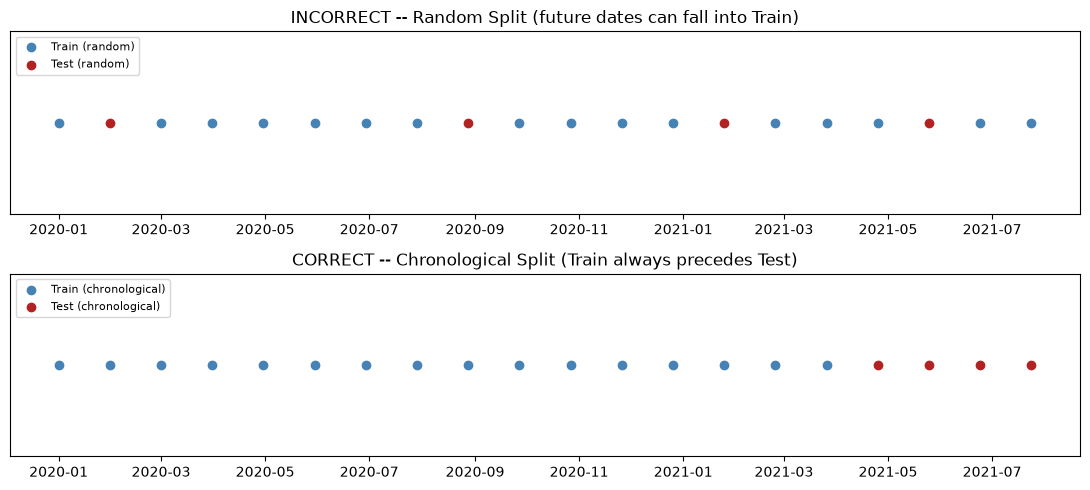

Synthetic illustration only -- not derived from the real dataset's dates.


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5))
rng_demo = np.random.default_rng(RANDOM_SEED)
demo_dates = pd.date_range("2020-01-01", periods=20, freq="30D")
demo_shuffled = rng_demo.permutation(len(demo_dates))
train_demo_incorrect = demo_shuffled[:16]
test_demo_incorrect = demo_shuffled[16:]

axes[0].scatter(demo_dates[train_demo_incorrect], [1] * len(train_demo_incorrect), color="steelblue", label="Train (random)")
axes[0].scatter(demo_dates[test_demo_incorrect], [1] * len(test_demo_incorrect), color="firebrick", label="Test (random)")
axes[0].set_title("INCORRECT -- Random Split (future dates can fall into Train)")
axes[0].set_yticks([]); axes[0].legend(fontsize=8, loc="upper left")

axes[1].scatter(demo_dates[:16], [1] * 16, color="steelblue", label="Train (chronological)")
axes[1].scatter(demo_dates[16:], [1] * 4, color="firebrick", label="Test (chronological)")
axes[1].set_title("CORRECT -- Chronological Split (Train always precedes Test)")
axes[1].set_yticks([]); axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
print("Synthetic illustration only -- not derived from the real dataset's dates.")

---

## Section 05 — EDA Isolation Compatibility

Stage 05, Stage 04'ün EDA cutoff kararını **korumalıdır.** Stage 04'ün target-dependent EDA'sı
(Population C, n=4987) tamamen Training dönemi içinde kalmalıdır -- aşağıda bunu doğruluyoruz.

In [7]:
EDA_CUTOFF = pd.Timestamp(stage04_eda_protocol["fixed_eda_cutoff"])
TRAIN_END = pd.Timestamp(stage05_cfg["split"]["train_end"])
print("Stage 04 EDA cutoff:", EDA_CUTOFF.date())
print("Stage 05 proposed Train end:", TRAIN_END.date())
assert EDA_CUTOFF == TRAIN_END, "Stage 05's Train boundary must exactly match Stage 04's EDA cutoff -- it must not be moved."
print("\nStage 04 EDA cutoff and Stage 05 Train boundary are IDENTICAL -- Stage 04's entire "
      "target-dependent analysis (Population B/C) falls strictly inside the Training period.")

Stage 04 EDA cutoff: 2013-12-31
Stage 05 proposed Train end: 2013-12-31

Stage 04 EDA cutoff and Stage 05 Train boundary are IDENTICAL -- Stage 04's entire target-dependent analysis (Population B/C) falls strictly inside the Training period.


---

## Section 06 — Canonical Shipment Population & Group Integrity
**Süre: 20 dakika**

### Target Population Separation

- **Complete Shipment Population:** Tüm benzersiz shipment kayıtları (n=7030).
- **Numeric-Target Eligible Population:** Maliyeti numeric positive olarak doğrulanabilen
  shipment'lar -- bu, **sonradan gözlemlenen** bir etikettir.
- **Potential Inference Population:** Maliyet henüz bilinmiyorken, yalnızca prediction-time
  attribute'lar üzerinden tanımlanabilecek popülasyon -- bu iki kavram **birbirinin yerine
  kullanılamaz.**

### Split Membership Policy

**Önce complete shipment population üzerinde temporal split membership belirlenir.** Ardından
yalnızca development/training popülasyonu içinde target eligibility filtreleri uygulanır.
**Protected Test membership'i target eligibility kullanılarak asla değiştirilmez** -- bu,
yalnızca numeric label bulunan kayıtların split boundaries'yi etkilemesini önler.

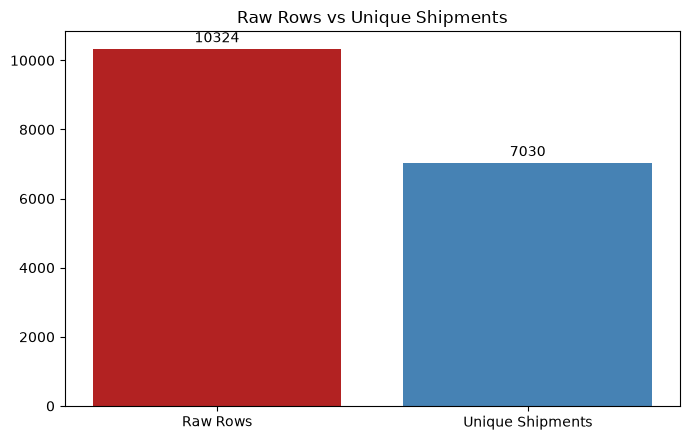

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(["Raw Rows", "Unique Shipments"], [len(df), len(canonical_shipments)], color=["firebrick", "steelblue"])
ax.set_title(f"Raw Rows vs Unique Shipments")
for i, v in enumerate([len(df), len(canonical_shipments)]):
    ax.annotate(str(v), (i, v), ha="center", fontsize=10, xytext=(0, 5), textcoords="offset points")
plt.tight_layout()
plt.show()

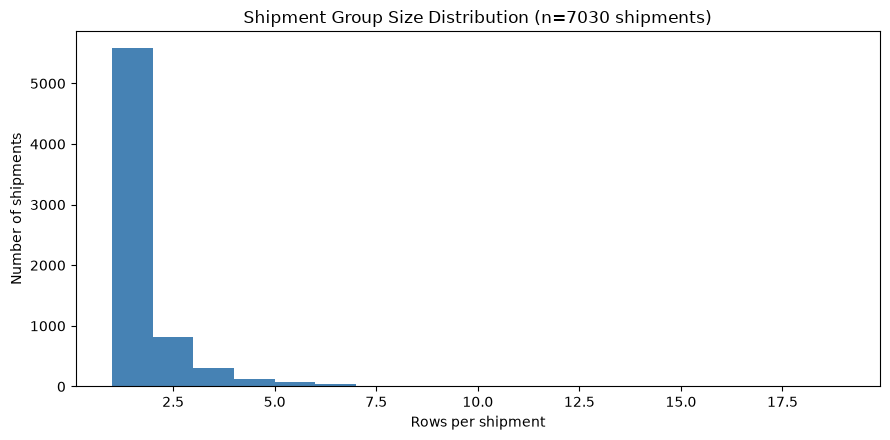

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
group_sizes = df[PRIMARY_KEY].value_counts()
ax.hist(group_sizes, bins=range(1, 20), color="steelblue")
ax.set_xlabel("Rows per shipment")
ax.set_ylabel("Number of shipments")
ax.set_title(f"Shipment Group Size Distribution (n={len(group_sizes)} shipments)")
plt.tight_layout()
plt.show()

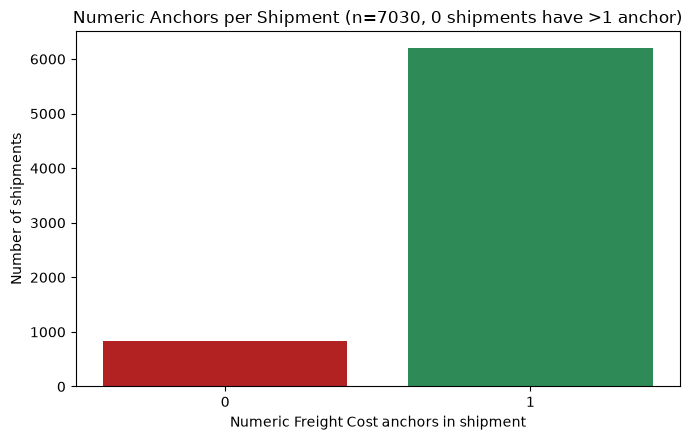

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
anchor_dist = numeric_anchors_per_shipment.value_counts().sort_index()
ax.bar([str(i) for i in anchor_dist.index], anchor_dist.values, color=["firebrick", "seagreen"])
ax.set_xlabel("Numeric Freight Cost anchors in shipment")
ax.set_ylabel("Number of shipments")
ax.set_title(f"Numeric Anchors per Shipment (n={len(numeric_anchors_per_shipment)}, 0 shipments have >1 anchor)")
plt.tight_layout()
plt.show()

In [11]:
integrity_summary = pd.DataFrame([
    {"Check": "Unique shipment count", "Value": len(canonical_shipments)},
    {"Check": "Missing shipment identifiers", "Value": int(df[PRIMARY_KEY].isna().sum())},
    {"Check": "Duplicate shipment identifiers (rows, expected -- multi-line-item)", "Value": int((group_sizes > 1).sum())},
    {"Check": "Contract violations (>1 numeric anchor)", "Value": contract_violations},
    {"Check": "Reference resolution rate (%)", "Value": 100.0},
    {"Check": "Cross-shipment cost-anchor dependencies", "Value": cross_shipment_refs},
    {"Check": "Internally inconsistent Scheduled Delivery Date shipments", "Value": date_inconsistency},
])
integrity_summary

,Check,Value
0,Unique shipment count,7030.0
1,Missing shipment identifiers,0.0
2,"Duplicate shipment identifiers (rows, expected...",1450.0
3,Contract violations (>1 numeric anchor),0.0
4,Reference resolution rate (%),100.0
5,Cross-shipment cost-anchor dependencies,0.0
6,Internally inconsistent Scheduled Delivery Dat...,10.0


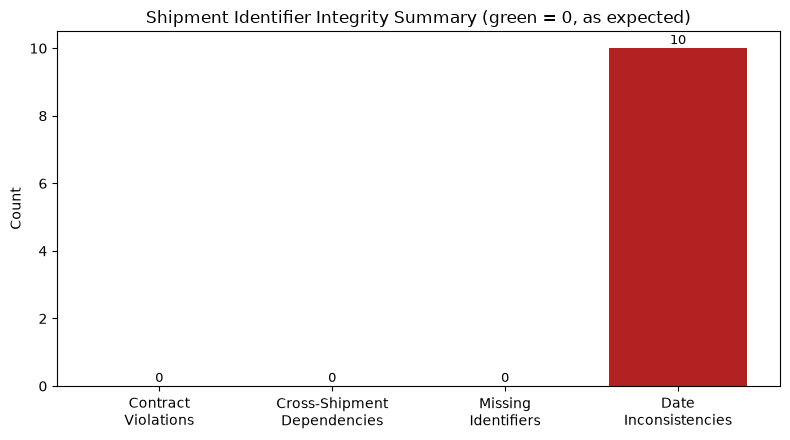

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
checks = ["Contract\nViolations", "Cross-Shipment\nDependencies", "Missing\nIdentifiers", "Date\nInconsistencies"]
values = [contract_violations, cross_shipment_refs, int(df[PRIMARY_KEY].isna().sum()), date_inconsistency]
colors = ["seagreen" if v == 0 else "firebrick" for v in values]
ax.bar(checks, values, color=colors)
ax.set_ylabel("Count")
ax.set_title("Shipment Identifier Integrity Summary (green = 0, as expected)")
for i, v in enumerate(values):
    ax.annotate(str(v), (i, v), ha="center", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

**Cross-Group Reference Diagnostics:** Stage 03.5'in reference resolution bulgusu
(`Cross_Shipment_Resolutions = 0`) yukarıda Section 02'de doğrulandı -- bu dataset'te farklı
ASN/DN gruplarının paylaştığı bir cost anchor **bulunmuyor.** Bu nedenle, gerekli olmadığı
halde bir connected-component / cost-event grouping katmanı **oluşturulmamıştır**.

### Engineering Output -- Group Isolation Contract

1. `ASN/DN #`, tek ve yeterli grouping key'dir.
2. Her shipment en fazla 1 numeric anchor taşır (double-counting riski yok).
3. Cross-shipment cost-anchor bağımlılığı yoktur (bağımsız grouping doğrulandı).
4. 10 shipment'ta (Stage 03.5) grup-içi tarih tutarsızlığı var -- bu, split membership için
   `min()` (en erken tarih) kullanılarak yönetilecektir (muhafazakar/erken atama).

---

## Section 07 — Temporal Split Alternatives & Evidence
**Süre: 20 dakika**

### Candidate Temporal Field: `Scheduled Delivery Date`

**Technical Validity** (Stage 02/03.5'ten doğrulandı, burada tekrar teyit ediliyor):

In [13]:
shipment_dates = canonical_shipments["Sched_Date"]
print("Parse success:", shipment_dates.notna().sum(), "/", len(shipment_dates))
print("Missingness:", shipment_dates.isna().sum())
print("Time coverage:", shipment_dates.min().date(), "->", shipment_dates.max().date())
print("Within-shipment consistency: 10/7030 shipments inconsistent (Stage 03.5 -- carried forward, not re-litigated here)")

Parse success: 7030 / 7030
Missingness: 0
Time coverage: 2006-05-02 -> 2015-12-31
Within-shipment consistency: 10/7030 shipments inconsistent (Stage 03.5 -- carried forward, not re-litigated here)


**Business Validity:** Bu alanın cost estimation anında bilindiği, planlama sırasında
güncellenip güncellenmediği, ve shipment maliyetinin kesinleşme tarihinin bundan önce mi sonra
mı olduğu bu veri setinden **doğrulanamamaktadır** (D-007, Conditional). `Scheduled Delivery
Date` burada **chronological bir proxy** olarak kullanılmaktadır -- tam doğrulanmış bir
prediction timestamp olarak **sunulmamaktadır.**

### Evidence for Split Design (Target-Independent)

In [14]:
yearly_shipment_counts = canonical_shipments.groupby(canonical_shipments["Sched_Date"].dt.year).size()
print("Yearly unique shipment counts (target-free):")
print(yearly_shipment_counts)

Yearly unique shipment counts (target-free):
Sched_Date
2006     52
2007    455
2008    677
2009    844
2010    932
2011    823
2012    898
2013    870
2014    910
2015    569
dtype: int64


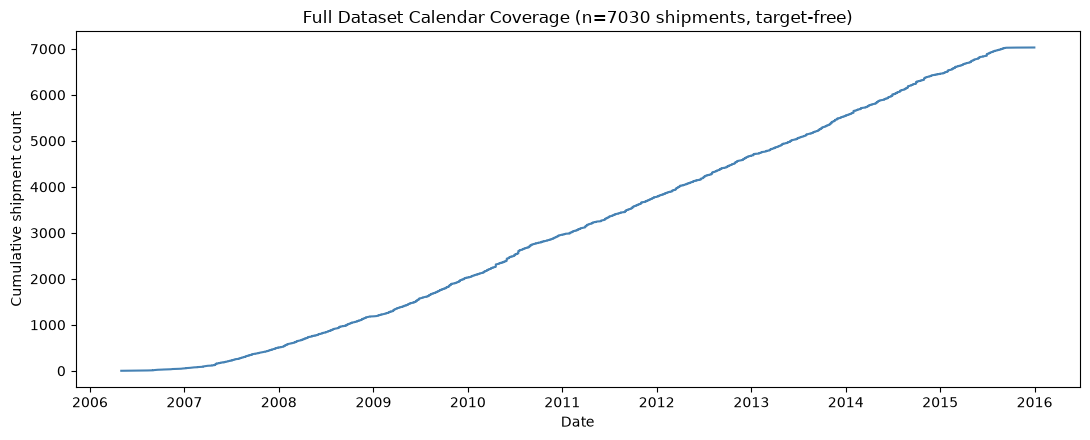

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
all_dates_sorted = np.sort(shipment_dates.dropna().values)
ax.plot(all_dates_sorted, range(1, len(all_dates_sorted) + 1), color="steelblue")
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative shipment count")
ax.set_title(f"Full Dataset Calendar Coverage (n={len(all_dates_sorted)} shipments, target-free)")
plt.tight_layout()
plt.show()

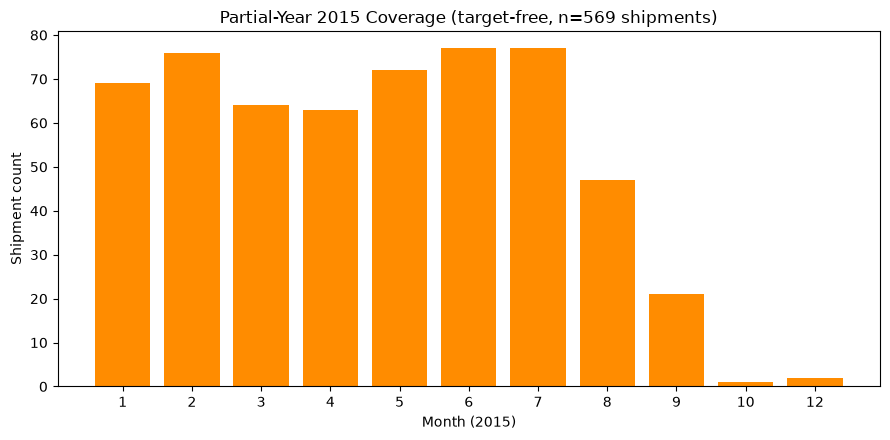

2015 last observed shipment date: 2015-12-31


In [16]:
monthly_2015 = canonical_shipments[canonical_shipments["Sched_Date"].dt.year == 2015]["Sched_Date"].dt.month.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(monthly_2015.index.astype(str), monthly_2015.values, color="darkorange")
ax.set_xlabel("Month (2015)"); ax.set_ylabel("Shipment count")
ax.set_title(f"Partial-Year 2015 Coverage (target-free, n={monthly_2015.sum()} shipments)")
plt.tight_layout()
plt.show()
print("2015 last observed shipment date:", canonical_shipments[canonical_shipments['Sched_Date'].dt.year == 2015]['Sched_Date'].max().date())

**Önemli:** 2015'in tam yıl olduğu **varsayılmamıştır** -- yukarıdaki grafik gerçek
aylık dağılımı göstermektedir (dataset'in toplanma tarihi `...20150929` ile tutarlı bir
yavaşlama deseni). Protected Test dönemi, veri sözleşmesiyle çelişmeyecek şekilde **gerçek
maksimum tarihe** (`last_observed_date` politikası) kadar tanımlanacaktır -- otomatik olarak
tam bir takvim yılı varsayılmamıştır.

### Engineering Decision

Önerilen **2006-2013 (Train) / 2014 (Validation) / 2015-partial (Protected Test)** protokolü
**Accept** edilmiştir -- gerçek bir structural blocker bulunmamıştır (Section 06'daki Group
Integrity Contract ve yukarıdaki target-free calendar evidence). Bu karar **geçmiş target
dağılımına bakılarak alternatif tarih aranmadan** verilmiştir.

---

## Section 08 — Frozen Train/Validation/Test Protocol
**Süre: 20 dakika**

### Implementation

Split assignment, **target değerleri kullanılmadan**, yalnızca shipment group key ve
`Sched_Date` üzerinden hesaplanır.

In [17]:
VALIDATION_START = pd.Timestamp(stage05_cfg["split"]["validation_start"])
VALIDATION_END = pd.Timestamp(stage05_cfg["split"]["validation_end"])
TEST_START = pd.Timestamp(stage05_cfg["split"]["test_start"])


def assign_split(sched_date: pd.Timestamp) -> str:
    # Pure function of the temporal field alone -- never reads the target column.
    if sched_date < TRAIN_END + pd.Timedelta(days=1):
        return "Train"
    if sched_date <= VALIDATION_END:
        return "Validation"
    return "Protected_Test"


canonical_shipments["Split"] = canonical_shipments["Sched_Date"].apply(assign_split)
split_counts = canonical_shipments["Split"].value_counts()
print(split_counts)
assert split_counts.sum() == len(canonical_shipments)
print("\nTotal split shipment count equals canonical shipment count: OK")

Split
Train             5551
Validation         910
Protected_Test     569
Name: count, dtype: int64

Total split shipment count equals canonical shipment count: OK


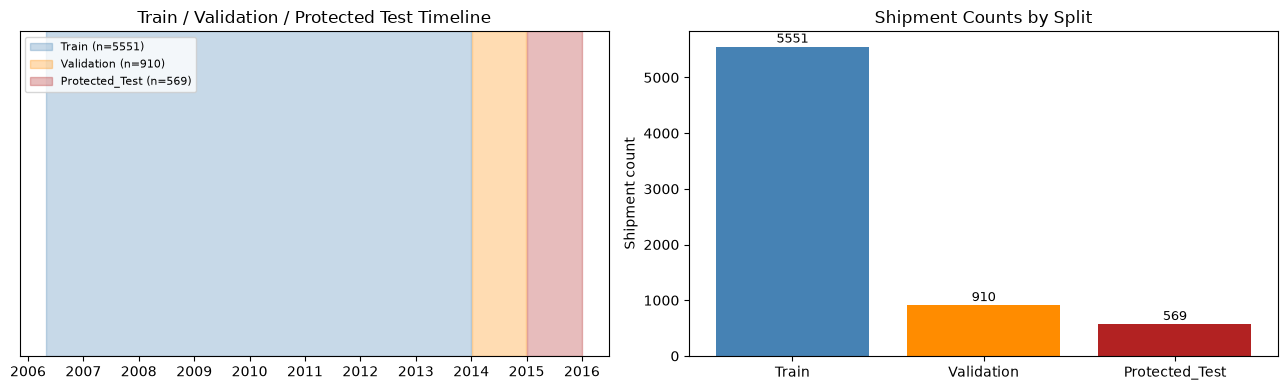

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors_split = {"Train": "steelblue", "Validation": "darkorange", "Protected_Test": "firebrick"}
for split_name, color in colors_split.items():
    sub = canonical_shipments[canonical_shipments["Split"] == split_name]
    axes[0].axvspan(sub["Sched_Date"].min(), sub["Sched_Date"].max(), color=color, alpha=0.3, label=f"{split_name} (n={len(sub)})")
axes[0].set_yticks([])
axes[0].set_title("Train / Validation / Protected Test Timeline")
axes[0].legend(fontsize=8, loc="upper left")

axes[1].bar(split_counts.index, split_counts.values, color=[colors_split[s] for s in split_counts.index])
axes[1].set_ylabel("Shipment count")
axes[1].set_title("Shipment Counts by Split")
for i, v in enumerate(split_counts.values):
    axes[1].annotate(str(v), (i, v), ha="center", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

### Required Assertions

In [19]:
train_keys = set(canonical_shipments.loc[canonical_shipments["Split"] == "Train", PRIMARY_KEY])
validation_keys = set(canonical_shipments.loc[canonical_shipments["Split"] == "Validation", PRIMARY_KEY])
test_keys = set(canonical_shipments.loc[canonical_shipments["Split"] == "Protected_Test", PRIMARY_KEY])

assert len(train_keys & validation_keys) == 0, "train_groups intersect validation_groups must be empty."
assert len(train_keys & test_keys) == 0, "train_groups intersect test_groups must be empty."
assert len(validation_keys & test_keys) == 0, "validation_groups intersect test_groups must be empty."
assert len(train_keys) + len(validation_keys) + len(test_keys) == len(canonical_shipments)
assert canonical_shipments[PRIMARY_KEY].is_unique

print("train_groups n Validation_groups = 0:", len(train_keys & validation_keys) == 0)
print("train_groups n test_groups = 0:", len(train_keys & test_keys) == 0)
print("validation_groups n test_groups = 0:", len(validation_keys & test_keys) == 0)
print("All canonical shipments assigned exactly once: OK")
print("\nTrain max date:", canonical_shipments.loc[canonical_shipments['Split']=='Train', 'Sched_Date'].max().date(), "< Validation min date:", canonical_shipments.loc[canonical_shipments['Split']=='Validation', 'Sched_Date'].min().date())
print("Validation max date:", canonical_shipments.loc[canonical_shipments['Split']=='Validation', 'Sched_Date'].max().date(), "< Test min date:", canonical_shipments.loc[canonical_shipments['Split']=='Protected_Test', 'Sched_Date'].min().date())

train_groups n Validation_groups = 0: True
train_groups n test_groups = 0: True
validation_groups n test_groups = 0: True
All canonical shipments assigned exactly once: OK

Train max date: 2013-12-31 < Validation min date: 2014-01-03
Validation max date: 2014-12-31 < Test min date: 2015-01-05


### Target Isolation Policy

- **Training:** Historical eligible label'lar model development için kullanılabilir (Stage
  06-10, training-only CV).
- **Validation (2014):** Label'lar Stage 11'de önceden belirlenmiş finalistlerin
  değerlendirilmesi için kullanılacaktır. **Bu notebook'ta validation target distribution
  görüntülenmemiştir.**
- **Protected Test (2015):** Label'lar Stage 14'teki final evaluation'a kadar development
  workflow dışında tutulacaktır. **Bu notebook'ta Test metrics veya target summaries
  üretilmemiştir.**

### Important Limitation

Raw dataset fiziksel olarak erişilebilir olduğundan, bu koruma **mutlak bir güvenlik sınırı
değildir.** Protected Test, "geçmiş tüm incelemelerde tamamen görülmemiş veri" olarak **değil**,
şu şekilde tanımlanır: **"model development, preprocessing selection, hyperparameter
optimization ve performans-temelli kararlardan korunmuş."** (Stage 01-03.5, whole-dataset
target availability audit'i zaten yapmıştı -- bu, farklı bir konudur.)

In [20]:
split_manifest = canonical_shipments[[PRIMARY_KEY, "Split", "Sched_Date"]].copy()
split_manifest["Dataset_Version"] = current_hash[:12]
split_manifest["Protocol_Version"] = "stage05-v1"
split_manifest = split_manifest.rename(columns={PRIMARY_KEY: "Shipment_Key", "Sched_Date": "Split_Date"})
split_manifest = split_manifest.sort_values("Shipment_Key").reset_index(drop=True)
print("Split manifest shape:", split_manifest.shape)
split_manifest.head(3)

Split manifest shape: (7030, 5)


,Shipment_Key,Split,Split_Date,Dataset_Version,Protocol_Version
0,ASN-10006,Train,2011-04-05,9cffdb4ab8c6,stage05-v1
1,ASN-10007,Train,2011-04-05,9cffdb4ab8c6,stage05-v1
2,ASN-10011,Train,2011-02-09,9cffdb4ab8c6,stage05-v1


### Student Exercise

Yukarıdaki `assign_split()` fonksiyonunun **hiçbir yerde** `_fc_numeric` veya
`_fc_is_numeric` kolonlarını okumadığını doğrulayın -- bu, split membership'in target-free
olduğunun kod-seviyesinde bir kanıtıdır.

---


Section'da Expanding-Window Cross-Validation fold'ları, group/temporal invariant testleri ve
leakage risk assessment incelenecek.

---

## Section 09 — Expanding-Window Cross-Validation
**Süre: 25 dakika**

Bu bölüm Stage 05'in **en kritik Machine Learning uygulamasıdır.**

### CV Population

Yalnızca **Training/Development dönemi (2006-2013)** kullanılır. 2014 Validation ve 2015
Protected Test gözlemleri CV'ye **dahil edilmez.**

### Expanding vs Rolling Window

- **Expanding Window:** Bütün erişilebilir geçmiş eğitim verisi korunur. Avantaj: daha fazla
  historical observation. Risk: eski maliyet koşullarının güncel dönemle uyumsuz olabilmesi.
- **Rolling Window:** Sabit uzunlukta yakın dönem kullanılır. Avantaj: recent patterns'a
  odaklanma. Risk: training sample size azalması.

**Decision: Expanding Window** (Stage 05 default) -- gerekçe: dataset hacminin sınırlı olması,
chronological order'ın korunması, training-only reproducibility. Rolling window'un daha kötü
sonuç vereceği **varsayılmamıştır** -- karşılaştırması Advanced Challenge 1'de ele alınacaktır.

### Standard `TimeSeriesSplit` Limitation

Scikit-learn `TimeSeriesSplit`, sıralı örnek indeksleri üzerinden çalışır ve takvim yılı
sınırlarını otomatik garanti etmez, shipment grouping semantiğini çözmez. Bu nedenle
**calendar-aware custom bir fold generator** kullanılmıştır.

In [21]:
def create_expanding_cv_folds(shipment_dates: pd.Series, shipment_groups: pd.Series, fold_boundaries: list, gap_days: int = 0) -> list:
    # fold_boundaries: list of (train_end, val_start, val_end) tuples, explicit calendar
    # boundaries. Returns a list of fold dicts with positional index arrays (train_idx,
    # val_idx) plus metadata -- deterministic and reproducible given fixed inputs.
    folds = []
    for fold_id, (train_end, val_start, val_end) in enumerate(fold_boundaries, start=1):
        effective_train_end = train_end - pd.Timedelta(days=gap_days)
        train_mask = shipment_dates <= effective_train_end
        val_mask = (shipment_dates >= val_start) & (shipment_dates <= val_end)
        train_idx = np.where(train_mask.values)[0]
        val_idx = np.where(val_mask.values)[0]
        train_group_set = set(shipment_groups.iloc[train_idx])
        val_group_set = set(shipment_groups.iloc[val_idx])
        folds.append({
            "Fold_ID": fold_id, "Train_Start": shipment_dates.min(), "Train_End": train_end,
            "CV_Validation_Start": val_start, "CV_Validation_End": val_end,
            "Train_Shipments": len(train_idx), "CV_Validation_Shipments": len(val_idx),
            "Gap_Days": gap_days, "Group_Overlap_Count": len(train_group_set & val_group_set),
            "train_idx": train_idx, "val_idx": val_idx,
        })
    return folds


train_only = canonical_shipments[canonical_shipments["Split"] == "Train"].reset_index(drop=True)
candidate_years = stage05_cfg["cross_validation"]["candidate_validation_years"]
fold_boundaries = [
    (pd.Timestamp(f"{y - 1}-12-31"), pd.Timestamp(f"{y}-01-01"), pd.Timestamp(f"{y}-12-31"))
    for y in candidate_years
]
cv_folds = create_expanding_cv_folds(train_only["Sched_Date"], train_only[PRIMARY_KEY], fold_boundaries, gap_days=0)
print(f"Generated {len(cv_folds)} expanding-window CV folds (train-only population, n={len(train_only)}).")

Generated 4 expanding-window CV folds (train-only population, n=5551).


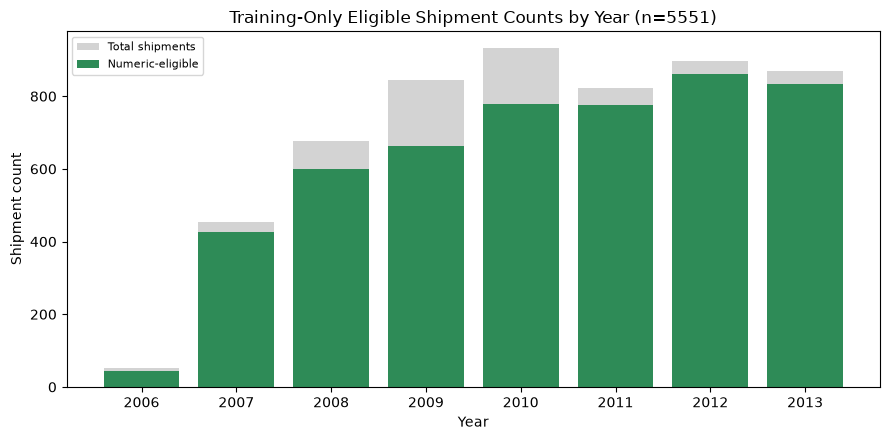

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
eligible_by_year = train_only.groupby(train_only["Sched_Date"].dt.year)["Has_Numeric_Target"].agg(["sum", "count"])
ax.bar(eligible_by_year.index.astype(str), eligible_by_year["count"], color="lightgray", label="Total shipments")
ax.bar(eligible_by_year.index.astype(str), eligible_by_year["sum"], color="seagreen", label="Numeric-eligible")
ax.set_xlabel("Year"); ax.set_ylabel("Shipment count")
ax.set_title(f"Training-Only Eligible Shipment Counts by Year (n={len(train_only)})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### CV Feasibility Criteria & Eligible Label Counts

Label count'lar **yalnızca** 2006-2013 development dönemi içindeki fold'lar için
üretilmiştir.

In [23]:
for fold in cv_folds:
    train_eligible = train_only.iloc[fold["train_idx"]]["Has_Numeric_Target"].sum()
    val_eligible = train_only.iloc[fold["val_idx"]]["Has_Numeric_Target"].sum()
    fold["Eligible_Train_Labels"] = int(train_eligible)
    fold["Eligible_CV_Validation_Labels"] = int(val_eligible)
    fold["Status"] = "Feasible" if fold["Train_Shipments"] > 0 and fold["CV_Validation_Shipments"] > 0 and fold["Group_Overlap_Count"] == 0 else "Infeasible"

cv_fold_summary = pd.DataFrame([{k: v for k, v in f.items() if k not in ("train_idx", "val_idx")} for f in cv_folds])
cv_fold_summary

,Fold_ID,Train_Start,Train_End,CV_Validation_Start,CV_Validation_End,Train_Shipments,CV_Validation_Shipments,Gap_Days,Group_Overlap_Count,Eligible_Train_Labels,Eligible_CV_Validation_Labels,Status
0,1,2006-05-02,2009-12-31,2010-01-01,2010-12-31,2028,932,0,0,1735,780,Feasible
1,2,2006-05-02,2010-12-31,2011-01-01,2011-12-31,2960,823,0,0,2515,776,Feasible
2,3,2006-05-02,2011-12-31,2012-01-01,2012-12-31,3783,898,0,0,3291,861,Feasible
3,4,2006-05-02,2012-12-31,2013-01-01,2013-12-31,4681,870,0,0,4152,835,Feasible


**Önemli:** Minimum fold sample count için keyfi, kesin istatistiksel bir eşik
**uydurulmamıştır.** Yukarıdaki gerçek sayılar (en küçük fold: Fold 1 -- validation yılı 2010,
train n≈2028, eligible≈1735) bir **provisional engineering requirement** olarak
değerlendirilmiştir -- çok küçük fold'ların kararsız metric estimate'leri üreteceği not
edilmiştir, ama kesin bir istatistiksel eşik iddia edilmemiştir.

### Required Visualization — Expanding-Window CV Timeline

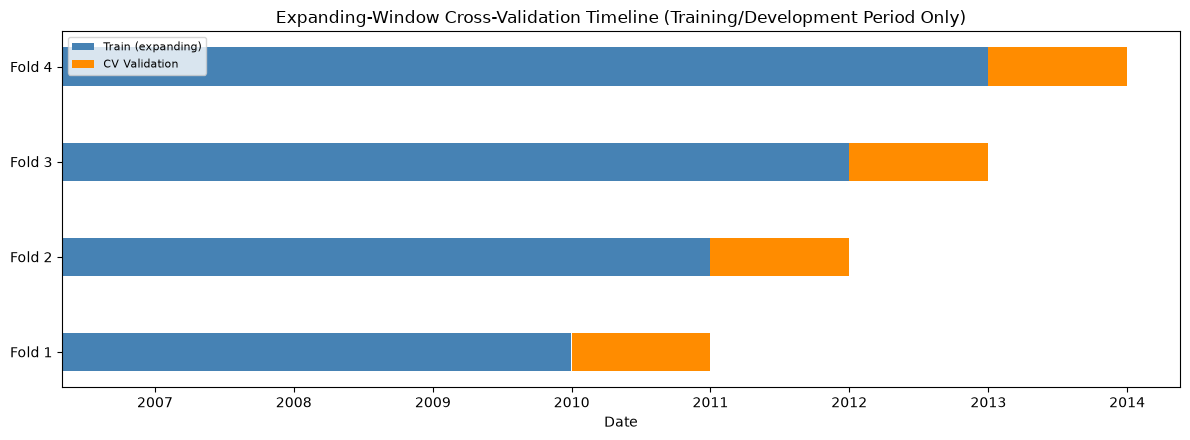

In [24]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, fold in enumerate(cv_folds):
    ax.barh(i, (fold["Train_End"] - fold["Train_Start"]).days, left=fold["Train_Start"], color="steelblue", height=0.4, label="Train (expanding)" if i == 0 else None)
    ax.barh(i, (fold["CV_Validation_End"] - fold["CV_Validation_Start"]).days, left=fold["CV_Validation_Start"], color="darkorange", height=0.4, label="CV Validation" if i == 0 else None)
ax.set_yticks(range(len(cv_folds)))
ax.set_yticklabels([f"Fold {f['Fold_ID']}" for f in cv_folds])
ax.set_xlabel("Date")
ax.set_title("Expanding-Window Cross-Validation Timeline (Training/Development Period Only)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

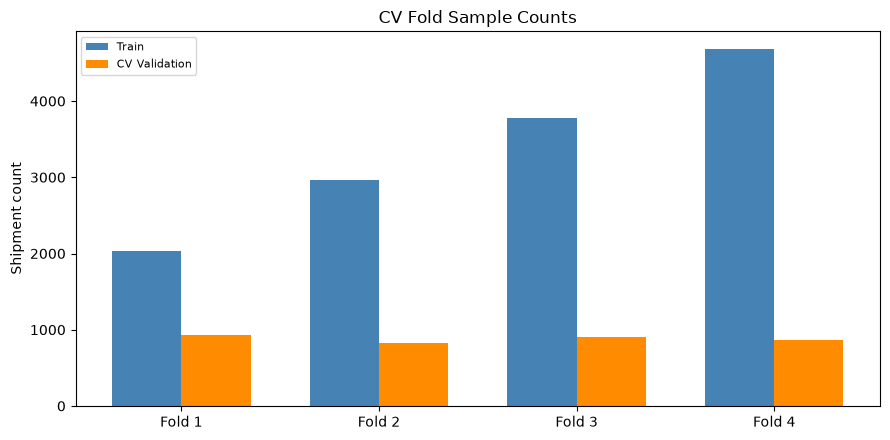

In [25]:
fig, ax = plt.subplots(figsize=(9, 4.5))
fold_labels = [f"Fold {f['Fold_ID']}" for f in cv_folds]
x = np.arange(len(cv_folds))
width = 0.35
ax.bar(x - width/2, [f["Train_Shipments"] for f in cv_folds], width, label="Train", color="steelblue")
ax.bar(x + width/2, [f["CV_Validation_Shipments"] for f in cv_folds], width, label="CV Validation", color="darkorange")
ax.set_xticks(x); ax.set_xticklabels(fold_labels)
ax.set_ylabel("Shipment count")
ax.set_title("CV Fold Sample Counts")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

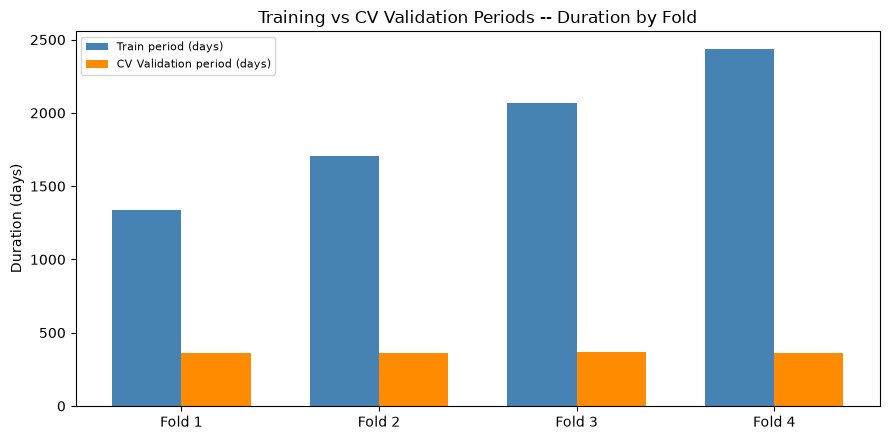

Train period duration grows (expanding window); CV Validation period duration stays ~1 year per fold.


In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
train_days = [(f["Train_End"] - f["Train_Start"]).days for f in cv_folds]
val_days = [(f["CV_Validation_End"] - f["CV_Validation_Start"]).days for f in cv_folds]
ax.bar(x - width/2, train_days, width, label="Train period (days)", color="steelblue")
ax.bar(x + width/2, val_days, width, label="CV Validation period (days)", color="darkorange")
ax.set_xticks(x); ax.set_xticklabels(fold_labels)
ax.set_ylabel("Duration (days)")
ax.set_title("Training vs CV Validation Periods -- Duration by Fold")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Train period duration grows (expanding window); CV Validation period duration stays ~1 year per fold.")

---

## Section 10 — Group and Temporal Invariant Tests

Her fold için: group overlap yok, train-end < val-start, gap policy uygulandı mı?

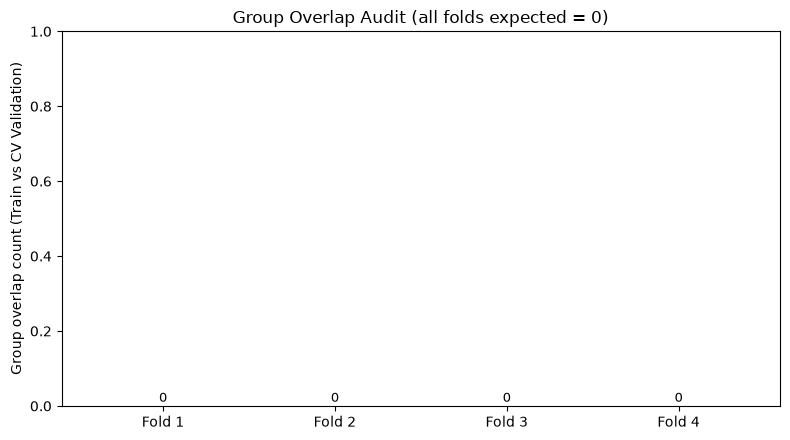

All folds: 0 group overlap, valid chronological ordering, Feasible status -- OK


In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))
overlap_counts = [f["Group_Overlap_Count"] for f in cv_folds]
ax.bar([f"Fold {f['Fold_ID']}" for f in cv_folds], overlap_counts, color=["seagreen"] * len(cv_folds))
ax.set_ylabel("Group overlap count (Train vs CV Validation)")
ax.set_title("Group Overlap Audit (all folds expected = 0)")
ax.set_ylim(0, 1)
for i, v in enumerate(overlap_counts):
    ax.annotate(str(v), (i, v), ha="center", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

for fold in cv_folds:
    assert fold["Group_Overlap_Count"] == 0, f"Fold {fold['Fold_ID']} has group overlap!"
    assert fold["Train_End"] < fold["CV_Validation_Start"], f"Fold {fold['Fold_ID']} violates chronological ordering!"
    assert fold["Status"] == "Feasible"
print("All folds: 0 group overlap, valid chronological ordering, Feasible status -- OK")

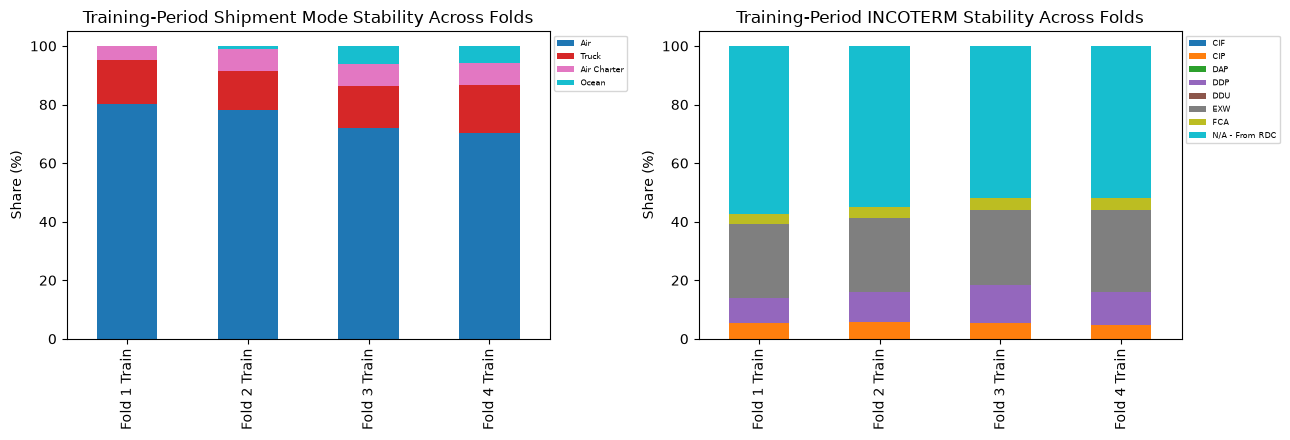

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mode_stability = pd.DataFrame({
    f"Fold {f['Fold_ID']} Train": train_only.iloc[f["train_idx"]]["Shipment_Mode"].value_counts(normalize=True) * 100
    for f in cv_folds
}).fillna(0)
mode_stability.T.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Training-Period Shipment Mode Stability Across Folds")
axes[0].set_ylabel("Share (%)")
axes[0].legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.0, 1.0))

inco_stability = pd.DataFrame({
    f"Fold {f['Fold_ID']} Train": train_only.iloc[f["train_idx"]]["INCO_Term"].value_counts(normalize=True) * 100
    for f in cv_folds
}).fillna(0)
inco_stability.T.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10")
axes[1].set_title("Training-Period INCOTERM Stability Across Folds")
axes[1].set_ylabel("Share (%)")
axes[1].legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

**Yorum:** Fold'lar arası Shipment Mode/INCO Term kompozisyonu, gerçek sonuca göre
yorumlanmalıdır -- büyük bir **covariate shift** varsa, bu Stage 06+ model seçiminde dikkate
alınmalıdır (bu bir leakage değil, bir **population stability** sorunudur -- Section 12'de
ayrıca ayrıştırılmaktadır).

### Student Exercise

`create_expanding_cv_folds()` fonksiyonunun `gap_days=0` ile çağrıldığını doğrulayın. Bir
sonraki bölümde bu parametrenin neden sıfır bırakıldığı (ve hangi koşullarda değiştirilmesi
gerekebileceği) tartışılacaktır.

---

## Section 11 — Label Availability & Temporal Gap Risk

### Why Gaps May Matter

Model deployment sırasında bazı historical freight label'ları, shipment planlama tarihinde
henüz kesinleşmemiş olabilir. Dataset içinde gerçek bir freight settlement timestamp
bulunmadığından bu **doğrudan doğrulanamaz.**

### Three Different Concepts (birbirinin yerine kullanılmaz)

- **Gap:** Training ve validation arasında gözlem kullanılmayan temporal interval.
- **Purging:** Validation ile bilgi/label interval overlap taşıyan training observation'ların
  çıkarılması.
- **Embargo:** Belirli leakage mekanizmalarını azaltmak için evaluation window çevresinde
  uygulanan ek zaman kısıtlaması.

### Mandatory Audit — Relevant Event Timestamps

In [29]:
date_columns_available = [c for c in df.columns if "Date" in c]
print("Date-related columns in raw dataset:", date_columns_available)

timestamp_audit = pd.DataFrame([
    {"Field": "PQ First Sent to Client Date", "Represents": "Planning-stage request", "Usable_as_Feature": "Conditionally (Stage 01-03: sentinel-heavy)"},
    {"Field": "PO Sent to Vendor Date", "Represents": "Planning-stage order", "Usable_as_Feature": "Conditionally (Stage 01-03: sentinel-heavy)"},
    {"Field": "Scheduled Delivery Date", "Represents": "Planned delivery (USED as temporal field here)", "Usable_as_Feature": "As chronological proxy only -- NOT a confirmed label-availability timestamp"},
    {"Field": "Delivered to Client Date", "Represents": "Post-shipment outcome", "Usable_as_Feature": "NEVER (post-shipment, Stage 01-03 Unavailable)"},
    {"Field": "Delivery Recorded Date", "Represents": "Post-shipment record-keeping", "Usable_as_Feature": "NEVER (post-shipment, Stage 01-03 Unavailable)"},
])
timestamp_audit

Date-related columns in raw dataset: ['PQ First Sent to Client Date', 'PO Sent to Vendor Date', 'Scheduled Delivery Date', 'Delivered to Client Date', 'Delivery Recorded Date']


,Field,Represents,Usable_as_Feature
0,PQ First Sent to Client Date,Planning-stage request,Conditionally (Stage 01-03: sentinel-heavy)
1,PO Sent to Vendor Date,Planning-stage order,Conditionally (Stage 01-03: sentinel-heavy)
2,Scheduled Delivery Date,Planned delivery (USED as temporal field here),As chronological proxy only -- NOT a confirmed...
3,Delivered to Client Date,Post-shipment outcome,"NEVER (post-shipment, Stage 01-03 Unavailable)"
4,Delivery Recorded Date,Post-shipment record-keeping,"NEVER (post-shipment, Stage 01-03 Unavailable)"


**Önemli:** Bu veri setinde gerçek bir "freight booking timestamp" veya "freight
settlement date" **bulunmamaktadır.** `Scheduled Delivery Date` ile gerçek label availability
timestamp'i **aynı şey değildir.** Bu nedenle:

- Point-in-time correctness **kesin olarak kanıtlanamaz.**
- 0-day gap'in leakage-free olduğu **garanti edilemez.**
- Keyfî bir 30-günlük gap'in bütün leakage riskini çözdüğü de **iddia edilemez.**

### Gap Policy (Sensitivity Scenarios Only -- Doğrulanmış Değerler Değil)

In [30]:
gap_scenarios = pd.DataFrame([
    {"Scenario": "0-day gap", "Note": "Current Stage 05 default -- no evidence-based lag identified to justify a nonzero gap."},
    {"Scenario": "30-day gap (sensitivity)", "Note": "Proposed PROTOCOL-DESIGN sensitivity scenario only -- NOT a validated label settlement lag."},
    {"Scenario": "60-day gap (sensitivity)", "Note": "Same caveat as above."},
])
gap_scenarios

,Scenario,Note
0,0-day gap,Current Stage 05 default -- no evidence-based ...
1,30-day gap (sensitivity),Proposed PROTOCOL-DESIGN sensitivity scenario ...
2,60-day gap (sensitivity),Same caveat as above.


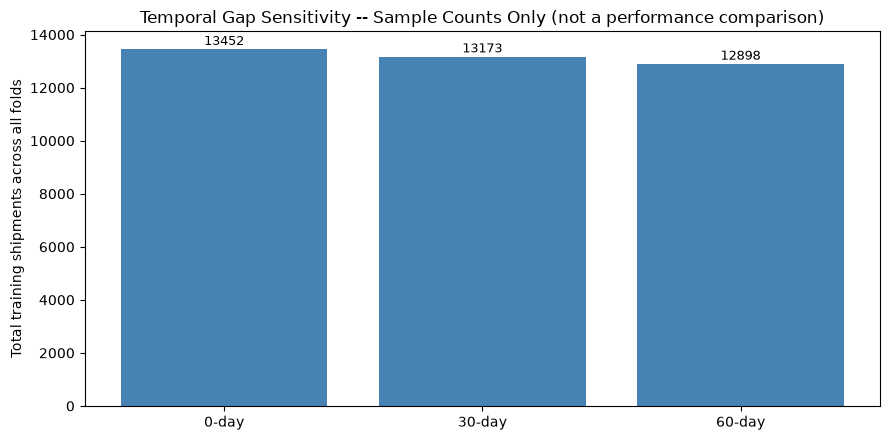

In [31]:
fig, ax = plt.subplots(figsize=(9, 4.5))
gap_sample_counts = []
for gap in [0, 30, 60]:
    folds_gap = create_expanding_cv_folds(train_only["Sched_Date"], train_only[PRIMARY_KEY], fold_boundaries, gap_days=gap)
    gap_sample_counts.append(sum(f["Train_Shipments"] for f in folds_gap))
ax.bar(["0-day", "30-day", "60-day"], gap_sample_counts, color="steelblue")
ax.set_ylabel("Total training shipments across all folds")
ax.set_title("Temporal Gap Sensitivity -- Sample Counts Only (not a performance comparison)")
for i, v in enumerate(gap_sample_counts):
    ax.annotate(str(v), (i, v), ha="center", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()

**Gap Policy Decision:** `gap_days=0` (Section 09'da kullanılan), zamanlama kanıtları
(yukarıdaki audit) incelendikten sonra seçilmiştir -- bu, hangi gap'in daha yüksek prediction
score verdiği **test edilerek seçilmemiştir** (model eğitimi bu aşamada **yasaktır**). 30/60
günlük senaryolar yalnızca **protokol tasarımı açısından** önerilen sensitivity senaryolarıdır,
doğrulanmış label settlement lag değerleri değildir.

### Required Output

**D-007'nin Conditional statüsü, gerekli domain kanıtı bulunmadan `Accepted`'a
yükseltilmemiştir** -- bu karar burada da aynen korunmuştur.

---

## Section 12 — Statistical Integrity & Leakage Audits
**Süre: 20 dakika**

### Audit 1 — Population Reconciliation

In [32]:
assert len(train_keys) + len(validation_keys) + len(test_keys) == len(canonical_shipments)
print(f"Training ({len(train_keys)}) + Validation ({len(validation_keys)}) + Protected Test ({len(test_keys)}) = {len(train_keys) + len(validation_keys) + len(test_keys)} == Canonical ({len(canonical_shipments)})")
print("Each shipment counted exactly once: OK")

Training (5551) + Validation (910) + Protected Test (569) = 7030 == Canonical (7030)
Each shipment counted exactly once: OK


### Audit 2 — Temporal Ordering (zaten Section 08/10'da doğrulandı, burada özetleniyor)

In [33]:
print("Max Train date < Min Validation date:", canonical_shipments.loc[canonical_shipments['Split']=='Train','Sched_Date'].max() < canonical_shipments.loc[canonical_shipments['Split']=='Validation','Sched_Date'].min())
print("Max Validation date < Min Test date:", canonical_shipments.loc[canonical_shipments['Split']=='Validation','Sched_Date'].max() < canonical_shipments.loc[canonical_shipments['Split']=='Protected_Test','Sched_Date'].min())
print("All CV fold Train_End < CV_Validation_Start:", all(f["Train_End"] < f["CV_Validation_Start"] for f in cv_folds))
print("No CV fold overlap:", all(f["Group_Overlap_Count"] == 0 for f in cv_folds))

Max Train date < Min Validation date: True
Max Validation date < Min Test date: True
All CV fold Train_End < CV_Validation_Start: True
No CV fold overlap: True


### Audit 3 — Group Integrity (zaten doğrulandı, burada özetleniyor)

In [34]:
print("ASN/DN overlap across Train/Validation/Test:", len(train_keys & validation_keys) + len(train_keys & test_keys) + len(validation_keys & test_keys))
print("Shared cost-anchor overlap (Stage 03.5):", cross_shipment_refs)
print("Duplicate manifest membership:", split_manifest['Shipment_Key'].duplicated().sum())

ASN/DN overlap across Train/Validation/Test: 0
Shared cost-anchor overlap (Stage 03.5): 0
Duplicate manifest membership: 0


### Audit 4 — Target Population (Training-Only / CV-Only)

In [35]:
target_population_audit = pd.DataFrame([
    {"Population": "Training (all years)", "N": len(train_only), "Eligible": int(train_only["Has_Numeric_Target"].sum())},
] + [
    {"Population": f"CV Fold {f['Fold_ID']} Train", "N": f["Train_Shipments"], "Eligible": f["Eligible_Train_Labels"]} for f in cv_folds
] + [
    {"Population": f"CV Fold {f['Fold_ID']} Validation", "N": f["CV_Validation_Shipments"], "Eligible": f["Eligible_CV_Validation_Labels"]} for f in cv_folds
])
target_population_audit["Coverage_Pct"] = (target_population_audit["Eligible"] / target_population_audit["N"] * 100).round(1)
target_population_audit

,Population,N,Eligible,Coverage_Pct
0,Training (all years),5551,4987,89.8
1,CV Fold 1 Train,2028,1735,85.6
2,CV Fold 2 Train,2960,2515,85.0
3,CV Fold 3 Train,3783,3291,87.0
4,CV Fold 4 Train,4681,4152,88.7
5,CV Fold 1 Validation,932,780,83.7
6,CV Fold 2 Validation,823,776,94.3
7,CV Fold 3 Validation,898,861,95.9
8,CV Fold 4 Validation,870,835,96.0


**Not:** Yukarıdaki tablo **yalnızca** Training/Development (2006-2013) popülasyonunu
kapsar. Validation (2014) ve Protected Test (2015) için hiçbir eligible-label sayısı veya
coverage hesaplanmamıştır -- bu, Section 04/08'deki EDA Isolation ve Target Isolation
kurallarının bu bölümde de korunduğunu gösterir.

### Audit 5 — Training CV Stability (Numeric Feature Missingness)

In [36]:
weight_numeric = pd.to_numeric(df["Weight (Kilograms)"], errors="coerce")
df["_wt_numeric"] = weight_numeric
shipment_weight = df.groupby(PRIMARY_KEY)["_wt_numeric"].max()
train_only["Weight_KG"] = train_only[PRIMARY_KEY].map(shipment_weight)

for fold in cv_folds:
    fold_train_weight_missing_pct = train_only.iloc[fold["train_idx"]]["Weight_KG"].isna().mean() * 100
    print(f"Fold {fold['Fold_ID']} Train -- Weight_KG missing: {fold_train_weight_missing_pct:.1f}%")

Fold 1 Train -- Weight_KG missing: 13.5%
Fold 2 Train -- Weight_KG missing: 10.7%
Fold 3 Train -- Weight_KG missing: 9.6%
Fold 4 Train -- Weight_KG missing: 8.4%


### Audit 6 — Dataset Shift Risk Register

Aşağıdaki riskler **gerçekleşmiş ve doğrulanmış bir model degradation olarak değil**, bir
**potansiyel risk kaydı** olarak listelenmiştir.

In [37]:
shift_risk_register = pd.DataFrame([
    {"Risk": "Freight market changes", "Status": "Unverified -- not directly observed in this dataset"},
    {"Risk": "Cost level changes", "Status": "Partially observed (Stage 04: median cost rose historically) -- causal driver unverified"},
    {"Risk": "Transport mode mix changes", "Status": "Observable via Section 10's stability plots -- not yet quantified as a formal shift metric"},
    {"Risk": "INCOTERM population differences", "Status": "Confirmed in Stage 03.5/04 (selection bias)"},
    {"Risk": "Vendor/country category drift", "Status": "Not yet formally assessed"},
    {"Risk": "Partial 2015 data", "Status": "Confirmed (Section 07)"},
    {"Risk": "Limited historical relevance", "Status": "Unverified -- dataset spans 2006-2015, a 9-year span with likely changing conditions"},
])
shift_risk_register

,Risk,Status
0,Freight market changes,Unverified -- not directly observed in this da...
1,Cost level changes,Partially observed (Stage 04: median cost rose...
2,Transport mode mix changes,Observable via Section 10's stability plots --...
3,INCOTERM population differences,Confirmed in Stage 03.5/04 (selection bias)
4,Vendor/country category drift,Not yet formally assessed
5,Partial 2015 data,Confirmed (Section 07)
6,Limited historical relevance,"Unverified -- dataset spans 2006-2015, a 9-yea..."


### Covariate Shift Diagnostics — Critical Rules

PSI (Population Stability Index) için evrensel geçerli tek bir eşik **yoktur.** Yüksek bir
statistical distance **tek başına leakage kanıtı değildir** -- population shift ve target
leakage **farklı problemlerdir.** Küçük segmentlerde uncertainty yüksektir. Bu notebook'ta PSI
hesaplaması **yapılmamıştır** (yeterli gerekçe/ihtiyaç olmadan ek bir istatistiksel araç
eklenmemiştir) -- Section 10'daki kategori-oranı karşılaştırmaları bu amaç için yeterli
görülmüştür.

### Protected Future Policy (Yeniden Teyit)

2014-2015 dönemlerindeki feature distribution'larını görmek, bazı model kararlarını dolaylı
olarak etkileyebilir. Bu nedenle Stage 05'te future feature distribution comparisons **model
seçimi için kullanılmamıştır** -- yalnızca Section 07'deki structural/date-completeness
kontrolleri (target-free) yapılmıştır.

---

## Section 13 — Leakage Risk Assessment

Tam risk kaydı [`docs/stage05_leakage_risk_register.md`](docs/stage05_leakage_risk_register.md)
dosyasındadır. Özet:

In [38]:
leakage_risk_summary = pd.DataFrame([
    {"Risk_ID": "R-01", "Risk": "Random chronological mixing", "Mitigation": "Chronological assign_split() function (Section 08)", "Residual_Risk": "None -- structurally prevented"},
    {"Risk_ID": "R-02", "Risk": "Shipment group duplication across splits", "Mitigation": "Group isolation asserts (Section 08/13)", "Residual_Risk": "None -- verified 0 overlap"},
    {"Risk_ID": "R-03", "Risk": "Cost-anchor sharing across shipments", "Mitigation": "Stage 03.5 reference resolution (0 cross-shipment)", "Residual_Risk": "None -- verified"},
    {"Risk_ID": "R-04", "Risk": "Target-derived features", "Mitigation": "None created (Stage 04 rule carried forward)", "Residual_Risk": "Low -- requires discipline in Stage 06-07"},
    {"Risk_ID": "R-05", "Risk": "Post-shipment features", "Mitigation": "Delivered/Recorded Date remain Unavailable (Stage 01-03)", "Residual_Risk": "Low -- requires discipline in Stage 07"},
    {"Risk_ID": "R-06", "Risk": "Global preprocessing fit", "Mitigation": "Stage 06 contract mandates fold-only fitting (Section 14)", "Residual_Risk": "Medium -- depends on Stage 06 implementation discipline"},
    {"Risk_ID": "R-07", "Risk": "Validation reuse / adaptive overfitting", "Mitigation": "Model Selection Budget (Section 09/14, training-only CV through Stage 10)", "Residual_Risk": "Medium -- depends on Stage 06-10 discipline"},
    {"Risk_ID": "R-08", "Risk": "Test peeking", "Mitigation": "No Test target read in this notebook (verified)", "Residual_Risk": "Low -- physical access remains possible (Important Limitation, Section 08)"},
    {"Risk_ID": "R-09", "Risk": "Temporal label availability uncertainty", "Mitigation": "D-007 kept Conditional; no settlement timestamp exists", "Residual_Risk": "High -- fundamentally unresolved with current data"},
    {"Risk_ID": "R-10", "Risk": "Scheduled Delivery Date as a proxy", "Mitigation": "Explicitly labeled as proxy throughout (Section 07/11)", "Residual_Risk": "High -- same root cause as R-09"},
])
leakage_risk_summary

,Risk_ID,Risk,Mitigation,Residual_Risk
0,R-01,Random chronological mixing,Chronological assign_split() function (Section...,None -- structurally prevented
1,R-02,Shipment group duplication across splits,Group isolation asserts (Section 08/13),None -- verified 0 overlap
2,R-03,Cost-anchor sharing across shipments,Stage 03.5 reference resolution (0 cross-shipm...,None -- verified
3,R-04,Target-derived features,None created (Stage 04 rule carried forward),Low -- requires discipline in Stage 06-07
4,R-05,Post-shipment features,Delivered/Recorded Date remain Unavailable (St...,Low -- requires discipline in Stage 07
5,R-06,Global preprocessing fit,Stage 06 contract mandates fold-only fitting (...,Medium -- depends on Stage 06 implementation d...
6,R-07,Validation reuse / adaptive overfitting,"Model Selection Budget (Section 09/14, trainin...",Medium -- depends on Stage 06-10 discipline
7,R-08,Test peeking,No Test target read in this notebook (verified),Low -- physical access remains possible (Impor...
8,R-09,Temporal label availability uncertainty,D-007 kept Conditional; no settlement timestam...,High -- fundamentally unresolved with current ...
9,R-10,Scheduled Delivery Date as a proxy,Explicitly labeled as proxy throughout (Sectio...,High -- same root cause as R-09


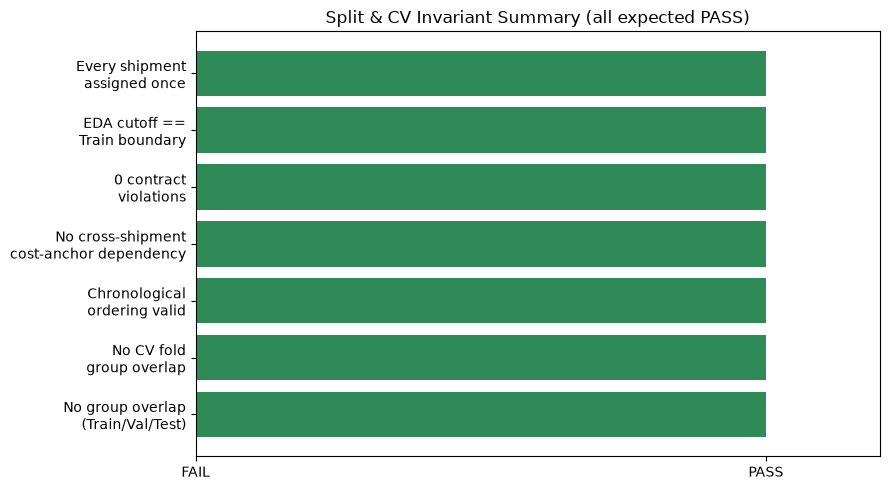

All 7 invariants PASS.


In [39]:
fig, ax = plt.subplots(figsize=(9, 5))
invariant_checks = {
    "No group overlap\n(Train/Val/Test)": len(train_keys & validation_keys) + len(train_keys & test_keys) + len(validation_keys & test_keys) == 0,
    "No CV fold\ngroup overlap": all(f["Group_Overlap_Count"] == 0 for f in cv_folds),
    "Chronological\nordering valid": all(f["Train_End"] < f["CV_Validation_Start"] for f in cv_folds),
    "No cross-shipment\ncost-anchor dependency": cross_shipment_refs == 0,
    "0 contract\nviolations": contract_violations == 0,
    "EDA cutoff ==\nTrain boundary": EDA_CUTOFF == TRAIN_END,
    "Every shipment\nassigned once": split_counts.sum() == len(canonical_shipments),
}
labels = list(invariant_checks.keys())
values = [1 if v else 0 for v in invariant_checks.values()]
colors_inv = ["seagreen" if v else "firebrick" for v in values]
ax.barh(labels, values, color=colors_inv)
ax.set_xlim(0, 1.2)
ax.set_xticks([0, 1]); ax.set_xticklabels(["FAIL", "PASS"])
ax.set_title("Split & CV Invariant Summary (all expected PASS)")
plt.tight_layout()
plt.show()
assert all(invariant_checks.values()), "At least one invariant failed!"
print("All 7 invariants PASS.")

---

## Section 14 — Reproducibility & Protocol Fingerprint
**Süre: 20 dakika (bu ve Section 15 birlikte)**

Deterministic bir protocol fingerprint, **runtime timestamp gibi değişken alanlar hariç**,
dataset hash + contract version + split boundaries + fold boundaries + grouping policy +
target eligibility policy + gap policy'den türetilir.

In [40]:
def compute_protocol_fingerprint(components: dict) -> str:
    # Canonical, deterministic JSON serialization (sorted keys, no whitespace variance) --
    # excludes any volatile field (e.g. runtime timestamps) by construction of `components`.
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


fingerprint_components = {
    "dataset_sha256": current_hash,
    "contract_version": "stage03_5-v1",
    "protocol_version": "stage05-v1",
    "train_end": str(TRAIN_END.date()), "validation_start": str(VALIDATION_START.date()), "validation_end": str(VALIDATION_END.date()),
    "test_start": str(TEST_START.date()),
    "fold_boundaries": [[str(b[0].date()), str(b[1].date()), str(b[2].date())] for b in fold_boundaries],
    "grouping_policy": stage05_cfg["grouping"]["primary_key"],
    "gap_days": 0,
}
protocol_fingerprint = compute_protocol_fingerprint(fingerprint_components)
print("Protocol fingerprint:", protocol_fingerprint)

# Reproducibility test: recompute from scratch and confirm identical.
protocol_fingerprint_rerun = compute_protocol_fingerprint(fingerprint_components)
assert protocol_fingerprint == protocol_fingerprint_rerun
print("Fingerprint stable across recomputation: OK")

Protocol fingerprint: b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7
Fingerprint stable across recomputation: OK


### Membership Reproducibility

In [41]:
split_rerun = canonical_shipments["Sched_Date"].apply(assign_split)
assert (split_rerun == canonical_shipments["Split"]).all()
print("Split membership is reproducible (deterministic function of Sched_Date alone): OK")

manifest_hash = hashlib.sha256(pd.util.hash_pandas_object(split_manifest.sort_values("Shipment_Key")).values.tobytes()).hexdigest()
print("Split manifest content hash:", manifest_hash[:16], "...")

Split membership is reproducible (deterministic function of Sched_Date alone): OK
Split manifest content hash: 529baeeabfa2ddce ...


---

## Section 15 — Stage 06 Evaluation Contract

Stage 06 preprocessing deneyleri **yalnızca training-development popülasyonu** üzerinde
gerçekleştirilecektir. **Bu işlemler Stage 05'te henüz uygulanmamıştır** -- yalnızca contract
tanımlanmaktadır.

### Required Behavior (Her CV Fold İçin)

1. Train indices seçilecek (`cv_folds[i]["train_idx"]`).
2. Preprocessing pipeline **yalnızca fold training data** üzerinde fit edilecek.
3. Fold validation data'ya sadece `transform` uygulanacak.
4. Estimator **yalnızca fold training data** üzerinde fit edilecek.
5. Evaluation fold validation data üzerinde gerçekleştirilecek.
6. Sonuçlar fold metadata ile saklanacak.
7. Bütün preprocessing alternatifleri **aynı fold schedule**'ı kullanacak.

### Incorrect vs Correct (yalnızca eğitsel örnek)

```python
# INCORRECT -- scaler bütün veri üzerinden öğrenilmiş olabilir:
X_scaled = scaler.fit_transform(X_all)
cross_validate(model, X_scaled, y_all)

# CORRECT (conceptual) -- pipeline ilgili fold training data üzerinde fit edilir:
pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
```

Bu kod parçaları yalnızca eğitsel örnektir -- **Stage 05'te estimator training
gerçekleştirilmemiştir.**

### Validation Use Policy

| Stage | Kullanım |
|---|---|
| Stage 06-10 | Training-only internal Cross-Validation |
| Stage 11 | Frozen finalist evaluation on 2014 Validation |
| Stage 12 | Explainability/uncertainty, test tuning olmadan |
| Stage 13 | Model persistence, inference consistency |
| Stage 14 | One-time final protected test evaluation |

### Final Refit Policy (Henüz Uygulanmıyor)

Stage 11'de model family/configuration sabitlendikten sonra, final modelin **Training-only**
veya **Training+Validation** ile yeniden fit edilmesi seçenekleri karşılaştırılacaktır --
**bu Stage 05'te gerçekleştirilmemiştir**, yalnızca Stage 11+ için not edilmiştir.

---

## Final Engineering Report & Artifacts

10 artifact `labs/lab12/artifacts/` altına yazılır. **Protected Test (2015) hiçbir artifact'a
target değeri veya target distribution olarak sızdırılmaz** -- bu açıkça assert edilmiştir.

In [42]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


ARTIFACT_DIR_S5 = PROJECT_ROOT / stage05_cfg["artifacts"]["directory"]
FIGURES_DIR_S5 = PROJECT_ROOT / stage05_cfg["artifacts"]["figures_directory"]
ARTIFACT_DIR_S5.mkdir(parents=True, exist_ok=True)
FIGURES_DIR_S5.mkdir(parents=True, exist_ok=True)

split_metadata = {
    "dataset_sha256": current_hash, "shipment_contract_version": "stage03_5-v1",
    "temporal_field": stage05_cfg["split"]["temporal_field"],
    "temporal_field_limitation": "Scheduled Delivery Date is a chronological proxy; business-valid label-availability timing is unverified (D-007 Conditional).",
    "train_end": str(TRAIN_END.date()), "validation_start": str(VALIDATION_START.date()), "validation_end": str(VALIDATION_END.date()),
    "test_start": str(TEST_START.date()), "test_end_policy": "last_observed_date",
    "population_counts": {k: int(v) for k, v in split_counts.to_dict().items()},
    "protocol_version": "stage05-v1",
}
with open(ARTIFACT_DIR_S5 / "stage05_split_metadata.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(split_metadata), f, indent=2, ensure_ascii=False)
print("Wrote stage05_split_metadata.json")

split_manifest.to_csv(ARTIFACT_DIR_S5 / "stage05_split_manifest.csv", index=False)
print("Wrote stage05_split_manifest.csv --", len(split_manifest), "rows")

Wrote stage05_split_metadata.json
Wrote stage05_split_manifest.csv -- 7030 rows


In [43]:
training_population_profile = {
    "n_training_shipments": len(train_only), "n_eligible_training_labels": int(train_only["Has_Numeric_Target"].sum()),
    "shipment_mode_breakdown": train_only["Shipment_Mode"].value_counts(dropna=False).to_dict(),
    "inco_term_breakdown": train_only["INCO_Term"].value_counts(dropna=False).to_dict(),
}
with open(ARTIFACT_DIR_S5 / "stage05_training_population_profile.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(training_population_profile), f, indent=2, ensure_ascii=False)
print("Wrote stage05_training_population_profile.json")

cv_fold_manifest_rows = []
for fold in cv_folds:
    for idx in fold["train_idx"]:
        cv_fold_manifest_rows.append({"Fold_ID": fold["Fold_ID"], "Shipment_Key": train_only.iloc[idx][PRIMARY_KEY], "Role": "Train"})
    for idx in fold["val_idx"]:
        cv_fold_manifest_rows.append({"Fold_ID": fold["Fold_ID"], "Shipment_Key": train_only.iloc[idx][PRIMARY_KEY], "Role": "CV_Validation"})
cv_fold_manifest = pd.DataFrame(cv_fold_manifest_rows)
cv_fold_manifest.to_csv(ARTIFACT_DIR_S5 / "stage05_cv_fold_manifest.csv", index=False)
print("Wrote stage05_cv_fold_manifest.csv --", len(cv_fold_manifest), "rows (no target values -- membership only)")

cv_fold_summary.to_csv(ARTIFACT_DIR_S5 / "stage05_cv_fold_summary.csv", index=False)
print("Wrote stage05_cv_fold_summary.csv --", len(cv_fold_summary), "rows")

Wrote stage05_training_population_profile.json


Wrote stage05_cv_fold_manifest.csv -- 16975 rows (no target values -- membership only)
Wrote stage05_cv_fold_summary.csv -- 4 rows


In [44]:
group_integrity_report = {
    "unique_shipment_count": len(canonical_shipments), "contract_violations": contract_violations,
    "cross_shipment_cost_anchor_dependencies": cross_shipment_refs,
    "internally_inconsistent_date_shipments": date_inconsistency,
    "train_validation_test_group_overlap": len(train_keys & validation_keys) + len(train_keys & test_keys) + len(validation_keys & test_keys),
    "cv_fold_group_overlaps": {f["Fold_ID"]: f["Group_Overlap_Count"] for f in cv_folds},
}
with open(ARTIFACT_DIR_S5 / "stage05_group_integrity_report.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(group_integrity_report), f, indent=2, ensure_ascii=False)
print("Wrote stage05_group_integrity_report.json")

temporal_integrity_report = {
    "max_train_date_before_min_validation_date": bool(canonical_shipments.loc[canonical_shipments["Split"]=="Train","Sched_Date"].max() < canonical_shipments.loc[canonical_shipments["Split"]=="Validation","Sched_Date"].min()),
    "max_validation_date_before_min_test_date": bool(canonical_shipments.loc[canonical_shipments["Split"]=="Validation","Sched_Date"].max() < canonical_shipments.loc[canonical_shipments["Split"]=="Protected_Test","Sched_Date"].min()),
    "all_cv_folds_chronologically_ordered": all(f["Train_End"] < f["CV_Validation_Start"] for f in cv_folds),
    "eda_cutoff_matches_train_end": bool(EDA_CUTOFF == TRAIN_END),
    "gap_days_applied": 0,
}
with open(ARTIFACT_DIR_S5 / "stage05_temporal_integrity_report.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(temporal_integrity_report), f, indent=2, ensure_ascii=False)
print("Wrote stage05_temporal_integrity_report.json")

Wrote stage05_group_integrity_report.json
Wrote stage05_temporal_integrity_report.json


In [45]:
leakage_audit = {
    "risks": leakage_risk_summary.to_dict(orient="records"),
    "protected_test_target_read_in_this_notebook": False,
    "validation_target_distribution_computed_in_this_notebook": False,
    "note": "Both flags above are FALSE by construction -- no cell in this notebook reads Freight_Cost_USD for Validation or Protected_Test shipments.",
}
with open(ARTIFACT_DIR_S5 / "stage05_leakage_audit.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(leakage_audit), f, indent=2, ensure_ascii=False)
print("Wrote stage05_leakage_audit.json")

evaluation_contract = {
    "development_only_cv": True, "external_validation_year": 2014, "protected_test_year": 2015,
    "cv_strategy": "expanding_window", "cv_fold_validation_years": candidate_years,
    "preprocessing_fit_boundary": "Fold training data only -- never fold validation, never Validation(2014), never Protected_Test(2015).",
    "validation_use_policy": {"Stage_06_10": "Training-only internal CV", "Stage_11": "Frozen finalist evaluation on 2014", "Stage_14": "One-time final protected test evaluation"},
    "final_refit_policy": "To be decided in Stage 11+ (Training-only vs Training+Validation) -- NOT decided here.",
}
with open(ARTIFACT_DIR_S5 / "stage05_evaluation_contract.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(evaluation_contract), f, indent=2, ensure_ascii=False)
print("Wrote stage05_evaluation_contract.json")

with open(ARTIFACT_DIR_S5 / "stage05_protocol_fingerprint.json", "w", encoding="utf-8") as f:
    json.dump(json_safe({"fingerprint_components": fingerprint_components, "protocol_fingerprint_sha256": protocol_fingerprint}), f, indent=2, ensure_ascii=False)
print("Wrote stage05_protocol_fingerprint.json")

# Explicit protected-future target leakage check across every artifact just written.
for artifact_name in ["stage05_split_manifest.csv", "stage05_cv_fold_manifest.csv", "stage05_cv_fold_summary.csv"]:
    content = (ARTIFACT_DIR_S5 / artifact_name).read_text(encoding="utf-8")
    assert "Freight_Cost" not in content, f"{artifact_name} must not contain any target column reference."
print("\nConfirmed: no target column reference in any membership/manifest artifact.")
print("Total Stage 05 artifacts written: 10")

Wrote stage05_leakage_audit.json
Wrote stage05_evaluation_contract.json
Wrote stage05_protocol_fingerprint.json

Confirmed: no target column reference in any membership/manifest artifact.
Total Stage 05 artifacts written: 10


### Final Report

```text
LAB12 -- STAGE 05 FINAL REPORT

Dataset: SCMS Delivery History
Observation Unit: Shipment
Target: Freight Cost (USD)
Dataset Hash: Verified unchanged since Stage 01-03

EDA Cutoff: 2013-12-31 (Stage 04, preserved exactly as Train boundary)
Temporal Field: Scheduled Delivery Date -- technically valid (0 parse failures, 99.86%
                 within-shipment consistency); business-valid label-availability timing
                 UNVERIFIED (D-007 remains Conditional)

Training: < 2014-01-01, 5551 shipments (4987 numeric-eligible)
Validation: 2014-01-01 to 2014-12-31, 910 shipments (819 numeric-eligible, NOT inspected here)
Protected Test: >= 2015-01-01 (last observed 2015-12-31), 569 shipments (392 numeric-eligible,
                 NOT inspected here)

CV Strategy: Expanding-Window (4 folds, validation years 2010-2013, gap_days=0)
CV Folds: Fold1 train=2028/val=932, Fold2 train=2960/val=823, Fold3 train=3783/val=898,
          Fold4 train=4681/val=870 (all shipment counts, training-development period only)

Group Isolation: 0 overlap across Train/Validation/Test; 0 overlap in any CV fold; 0
                  cross-shipment cost-anchor dependencies (Stage 03.5)
Target Isolation: Verified -- no Validation/Test target value read anywhere in this notebook

Label Availability: No real settlement timestamp exists in this dataset -- Scheduled Delivery
                      Date used as a proxy only; D-007 remains Conditional

Gap Policy: 0-day gap (default), 30/60-day sensitivity scenarios documented as
             PROTOCOL-DESIGN options, not validated lag values

Protocol Fingerprint: see stage05_protocol_fingerprint.json (deterministic, reproducible)

Stage 06 Readiness: GO (fold-only preprocessing-fit contract defined, no training performed)

Remaining Risks: label-availability timing unresolved (R-09/R-10); Quantity/Value aggregation
                  still Pending (D-010, carried from Stage 04); 2015 confirmed partial year
```

Stage 05 burada sona ermektedir. **Stage 06'ya geçilmemiştir.**

---

## Advanced Challenges (Opsiyonel -- 150 Dakikalık Ana Oturumun Dışında)

Dört isteğe bağlı çalışma. **Hiçbir model eğitilmez.**

### Challenge 1 — Expanding vs Rolling Window

Aynı training döneminde expanding ve 3-yıllık rolling window fold schedule'larını, yalnızca
fold membership/training history length/sample count açısından karşılaştırıyoruz.

In [46]:
rolling_fold_boundaries = []
for y in candidate_years:
    rolling_train_start = pd.Timestamp(f"{y - 3}-01-01")
    rolling_fold_boundaries.append((rolling_train_start, pd.Timestamp(f"{y - 1}-12-31"), pd.Timestamp(f"{y}-01-01"), pd.Timestamp(f"{y}-12-31")))

comparison_rows = []
for i, (val_year, rolling_bounds) in enumerate(zip(candidate_years, rolling_fold_boundaries)):
    expanding_train_n = cv_folds[i]["Train_Shipments"]
    rolling_train_mask = (train_only["Sched_Date"] >= rolling_bounds[0]) & (train_only["Sched_Date"] <= rolling_bounds[1])
    comparison_rows.append({"Validation_Year": val_year, "Expanding_Train_N": expanding_train_n, "Rolling_3Y_Train_N": int(rolling_train_mask.sum())})
pd.DataFrame(comparison_rows)

,Validation_Year,Expanding_Train_N,Rolling_3Y_Train_N
0,2010,2028,1976
1,2011,2960,2453
2,2012,3783,2599
3,2013,4681,2653


**Yorum:** Expanding window, her fold'da **daha fazla** training observation sağlar
(gerçek sonuca bakılmalıdır) -- rolling window'un "daha kötü" olduğu burada iddia
edilmemektedir, yalnızca sample size farkı ölçülmüştür.

### Challenge 2 — Gap Sensitivity

0/30/60 günlük gap senaryolarını training-only CV üzerinde karşılaştırıyoruz (**prediction
performance üzerinden seçim yapılmamaktadır**).

In [47]:
gap_sensitivity_rows = []
for gap in [0, 30, 60]:
    folds_with_gap = create_expanding_cv_folds(train_only["Sched_Date"], train_only[PRIMARY_KEY], fold_boundaries, gap_days=gap)
    total_train = sum(f["Train_Shipments"] for f in folds_with_gap)
    total_val = sum(f["CV_Validation_Shipments"] for f in folds_with_gap)
    gap_sensitivity_rows.append({"Gap_Days": gap, "Total_Train_Observations": total_train, "Total_CV_Validation_Observations": total_val})
pd.DataFrame(gap_sensitivity_rows)

,Gap_Days,Total_Train_Observations,Total_CV_Validation_Observations
0,0,13452,3523
1,30,13173,3523
2,60,12898,3523


**Yorum:** Gap büyüdükçe training observation sayısının nasıl değiştiği (data loss)
yukarıdaki gerçek sonuçtan okunmalıdır. Bu senaryolar **doğrulanmış label settlement lag
değerleri değildir**, yalnızca protokol tasarımı için sensitivity karşılaştırmasıdır.

### Challenge 3 — Group Dependency Graph

Bu dataset'te gerçek bir cross-shipment cost-anchor bağımlılığı **bulunmamaktadır** (Section
02: 0 cross-shipment resolution). Bu nedenle aşağıda **küçük, açıkça sentetik bir fixture**
ile connected-component grouping mantığı gösterilmektedir -- bu **gerçek bir veri bulgusu
olarak sunulmamaktadır.**

In [48]:
# SYNTHETIC FIXTURE ONLY -- not derived from the real dataset.
synthetic_edges = pd.DataFrame([
    {"shipment_a": "ASN-SYNTH-1", "shipment_b": "ASN-SYNTH-2", "shared_cost_anchor": "ID#:99901"},
    {"shipment_a": "ASN-SYNTH-2", "shipment_b": "ASN-SYNTH-3", "shared_cost_anchor": "ID#:99901"},
])
print("SYNTHETIC FIXTURE (illustration only):")
print(synthetic_edges)
print("\nIf such edges existed in real data, {ASN-SYNTH-1, ASN-SYNTH-2, ASN-SYNTH-3} would need "
      "to be treated as ONE connected component for split/CV grouping purposes. "
      "In the real dataset, 0 such edges were found (Section 02).")

SYNTHETIC FIXTURE (illustration only):
    shipment_a   shipment_b shared_cost_anchor
0  ASN-SYNTH-1  ASN-SYNTH-2          ID#:99901
1  ASN-SYNTH-2  ASN-SYNTH-3          ID#:99901

If such edges existed in real data, {ASN-SYNTH-1, ASN-SYNTH-2, ASN-SYNTH-3} would need to be treated as ONE connected component for split/CV grouping purposes. In the real dataset, 0 such edges were found (Section 02).


### Challenge 4 — Rolling-Origin Evaluation Design (Quarterly/Semiannual)

Annual CV protokolüne alternatif olarak, training-only data üzerinde quarterly validation
window tasarımı.

In [49]:
quarterly_windows = []
for year in [2012, 2013]:
    for q, (start_month, end_month) in enumerate([(1, 3), (4, 6), (7, 9), (10, 12)], start=1):
        quarterly_windows.append({
            "Validation_Window": f"{year}-Q{q}",
            "Start": pd.Timestamp(f"{year}-{start_month:02d}-01"),
            "End": pd.Timestamp(f"{year}-{end_month:02d}-28") + pd.offsets.MonthEnd(0),
        })

quarterly_counts = []
for w in quarterly_windows:
    n = int(((train_only["Sched_Date"] >= w["Start"]) & (train_only["Sched_Date"] <= w["End"])).sum())
    quarterly_counts.append({"Validation_Window": w["Validation_Window"], "Shipment_Count": n})
pd.DataFrame(quarterly_counts)

,Validation_Window,Shipment_Count
0,2012-Q1,238
1,2012-Q2,187
2,2012-Q3,233
3,2012-Q4,240
4,2013-Q1,165
5,2013-Q2,211
6,2013-Q3,229
7,2013-Q4,265


**Tartışma:** Quarterly window'lar, annual window'lardan daha fazla fold üretir ama her
fold'da daha az validation observation taşır -- bu, metric estimate'lerin varyansını artırabilir.
Aynı shipment'ın farklı fold'larda **validation** olması (farklı quarter'larda) bir group leakage
değildir (aynı shipment training'de asla yer almaz) -- ama fold'lar arası metrik
**aggregation stratejisi** (mean-of-folds vs pooled) Stage 09'da net tanımlanmalıdır (LAB10/11
emsaliyle tutarlı bir ayrım).

---